# Capacidade de Geração Elétrica — ANEEL

Parte do projeto **O Impacto dos Data Centers na Demanda Elétrica Brasileira até 2036: Uma Análise com Dados do ONS, ANEEL e EPE**. A fotografia SIGA de 09/11/2026 registra potência fiscalizada em operação e potência outorgada de projetos. Capacidade cadastrada, energia gerada e garantia de atendimento são grandezas distintas; projetos não operacionais não têm entrada assegurada em 2036.

Contém informações do [SIGA — ANEEL](https://dadosabertos.aneel.gov.br/dataset/siga-sistema-de-informacoes-de-geracao-da-aneel), disponibilizadas sob a [Open Database License (ODbL)](https://opendatacommons.org/licenses/odbl/1-0/). Os dados foram validados, deduplicados e agregados por este projeto.


## 1. Carregamento e Inspeção dos Dados
Leitura e avaliação da estrutura do arquivo SIGA.

In [1]:

import pandas as pd
from pathlib import Path

BASE_DIR = Path.cwd()

if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent

ARQUIVO = (
    BASE_DIR / "data" / "raw" / "aneel" /
    "siga_empreendimentos_diario.csv"
)

df_aneel = pd.read_csv(
    ARQUIVO,
    sep=";",
    encoding="utf-8-sig",
    low_memory=False
)

print("Dimensões:", df_aneel.shape)

print("\nColunas disponíveis:")
print(df_aneel.columns.tolist())

print("\nTipos de dados:")
df_aneel.info()

print("\nValores ausentes:")
display(df_aneel.isna().sum())


Dimensões: (24853, 23)

Colunas disponíveis:
['DatGeracaoConjuntoDados', 'NomEmpreendimento', 'IdeNucleoCEG', 'CodCEG', 'SigUFPrincipal', 'SigTipoGeracao', 'DscFaseUsina', 'DscOrigemCombustivel', 'DscFonteCombustivel', 'DscTipoOutorga', 'NomFonteCombustivel', 'DatEntradaOperacao', 'MdaPotenciaOutorgadaKw', 'MdaPotenciaFiscalizadaKw', 'MdaGarantiaFisicaKw', 'IdcGeracaoQualificada', 'NumCoordNEmpreendimento', 'NumCoordEEmpreendimento', 'DatInicioVigencia', 'DatFimVigencia', 'DscPropriRegimePariticipacao', 'DscSubBacia', 'DscMuninicpios']

Tipos de dados:
<class 'pandas.DataFrame'>
RangeIndex: 24853 entries, 0 to 24852
Data columns (total 23 columns):
 #   Column                        Non-Null Count  Dtype
---  ------                        --------------  -----
 0   DatGeracaoConjuntoDados       24853 non-null  str  
 1   NomEmpreendimento             24853 non-null  str  
 2   IdeNucleoCEG                  24853 non-null  int64
 3   CodCEG                        24853 non-null  str  
 

DatGeracaoConjuntoDados             0
NomEmpreendimento                   0
IdeNucleoCEG                        0
CodCEG                              0
SigUFPrincipal                      0
SigTipoGeracao                      0
DscFaseUsina                        0
DscOrigemCombustivel                0
DscFonteCombustivel                 0
DscTipoOutorga                      0
NomFonteCombustivel                 0
DatEntradaOperacao                  0
MdaPotenciaOutorgadaKw              0
MdaPotenciaFiscalizadaKw            0
MdaGarantiaFisicaKw                 0
IdcGeracaoQualificada           15957
NumCoordNEmpreendimento             0
NumCoordEEmpreendimento             0
DatInicioVigencia               19708
DatFimVigencia                  19718
DscPropriRegimePariticipacao        0
DscSubBacia                     23396
DscMuninicpios                      0
dtype: int64

## 2. Situação dos Empreendimentos
Identificação das fases operacionais das usinas.

In [2]:

print("Fases dos empreendimentos:")

display(
    df_aneel["DscFaseUsina"]
    .value_counts(dropna=False)
)

print("\nTipos de geração:")

display(
    df_aneel["SigTipoGeracao"]
    .value_counts(dropna=False)
)


Fases dos empreendimentos:


DscFaseUsina
Operação                   22854
Construção não iniciada     1873
Construção                   126
Name: count, dtype: int64


Tipos de geração:


SigTipoGeracao
UFV    18728
UTE     3104
EOL     1539
CGH      723
PCH      535
UHE      221
UTN        3
Name: count, dtype: int64

In [3]:

colunas_potencia = [
    "MdaPotenciaFiscalizadaKw",
    "MdaPotenciaOutorgadaKw"
]

for coluna in colunas_potencia:
    print(f"\n{coluna}")
    print("Tipo:", df_aneel[coluna].dtype)

    display(
        df_aneel[coluna].head(10)
    )



MdaPotenciaFiscalizadaKw
Tipo: int64


0      1400
1      3972
2      1440
3    100000
4       720
5      1460
6    102890
7     14040
8     14040
9       224
Name: MdaPotenciaFiscalizadaKw, dtype: int64


MdaPotenciaOutorgadaKw
Tipo: str


0      1400,00
1      3972,00
2      1440,00
3    100000,00
4       720,00
5      1460,00
6    102890,00
7     14040,00
8     14040,00
9       224,80
Name: MdaPotenciaOutorgadaKw, dtype: str

## 3. Análise de Duplicidades
Investigação de códigos CEG repetidos antes da transformação.

In [4]:

# Identificar códigos CEG repetidos
duplicados = df_aneel[
    df_aneel.duplicated(
        subset=["CodCEG"],
        keep=False
    )
].copy()

print("Total de registros:", len(df_aneel))

print(
    "Registros com CEG repetido:",
    len(duplicados)
)

print(
    "Códigos CEG distintos repetidos:",
    duplicados["CodCEG"].nunique()
)

print(
    "Linhas completamente idênticas:",
    df_aneel.duplicated().sum()
)

# Distribuição de frequências, sem divulgar identificadores individuais.
print("\nQuantidade de CEGs por número de registros:")
display(
    duplicados["CodCEG"].value_counts()
    .value_counts().sort_index()
    .rename_axis("registros_por_ceg")
    .rename("quantidade_cegs")
)


Total de registros: 24853
Registros com CEG repetido: 8
Códigos CEG distintos repetidos: 4


Linhas completamente idênticas:

 0

Quantidade de CEGs por número de registros:


registros_por_ceg
2    4
Name: quantidade_cegs, dtype: int64

## 4. Visualização 09 - Capacidade Instalada por Fonte
Distribuição da potência fiscalizada dos empreendimentos em operação.

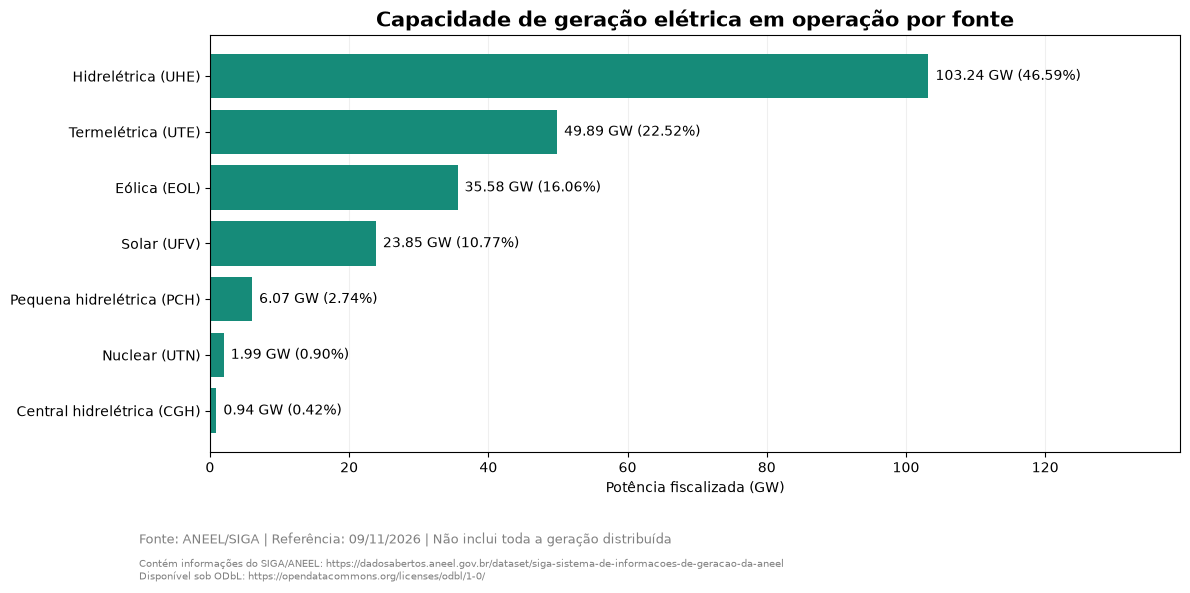

In [5]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Localizar a raiz do projeto
BASE_DIR = Path.cwd()

if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent

# Carregar a Gold da ANEEL
df_fontes = pd.read_parquet(
    BASE_DIR / "data" / "gold" / "aneel"
    / "capacidade_por_fonte.parquet"
)

# Consolidar por tipo de geração
df_grafico = (
    df_fontes.groupby("tipo_geracao", as_index=False)
    .agg(potencia_mw=("potencia_mw", "sum"))
    .sort_values("potencia_mw", ascending=True)
)

total_mw = df_grafico["potencia_mw"].sum()

df_grafico["participacao_pct"] = (
    df_grafico["potencia_mw"] / total_mw * 100
)

# Descrições das tecnologias
nomes = {
    "UHE": "Hidrelétrica (UHE)",
    "UTE": "Termelétrica (UTE)",
    "EOL": "Eólica (EOL)",
    "UFV": "Solar (UFV)",
    "PCH": "Pequena hidrelétrica (PCH)",
    "UTN": "Nuclear (UTN)",
    "CGH": "Central hidrelétrica (CGH)"
}

df_grafico["fonte"] = (
    df_grafico["tipo_geracao"].map(nomes)
)

# Criar gráfico
fig, ax = plt.subplots(figsize=(12, 6))

barras = ax.barh(
    df_grafico["fonte"],
    df_grafico["potencia_mw"] / 1000,
    color="#168B79"
)

# Rótulos de potência e participação
rotulos = [
    f"{mw / 1000:,.2f} GW ({pct:.2f}%)"
    for mw, pct in zip(
        df_grafico["potencia_mw"],
        df_grafico["participacao_pct"]
    )
]

ax.bar_label(
    barras,
    labels=rotulos,
    padding=5,
    fontsize=10
)

ax.set_xlim(
    0,
    df_grafico["potencia_mw"].max() / 1000 * 1.35
)

ax.set_title(
    "Capacidade de geração elétrica em operação por fonte",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Potência fiscalizada (GW)")
ax.set_ylabel("")

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

fig.text(
    0.12, 0.085,
    "Fonte: ANEEL/SIGA | Referência: 09/11/2026 | "
    "Não inclui toda a geração distribuída",
    fontsize=9,
    color="gray"
)

fig.text(
    0.12, 0.025,
    "Contém informações do SIGA/ANEEL: https://dadosabertos.aneel.gov.br/dataset/siga-sistema-de-informacoes-de-geracao-da-aneel\n"
    "Disponível sob ODbL: https://opendatacommons.org/licenses/odbl/1-0/",
    fontsize=7.5,
    color="gray"
)

plt.tight_layout(rect=[0, 0.14, 1, 1])

# Salvar gráfico
PASTA_IMAGENS = BASE_DIR / "images"
PASTA_IMAGENS.mkdir(exist_ok=True)

plt.savefig(
    PASTA_IMAGENS / "09_capacidade_por_fonte.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 5. Visualização 10 - Capacidade Instalada por Estado
Ranking dos dez estados com maior potência fiscalizada em operação.

Top 10 estados:


,uf,potencia_mw,potencia_gw
25,SP,25454.783,25.454783
10,MG,25268.04,25.26804
13,PA,23470.439,23.470439
4,BA,22195.407,22.195407
17,PR,17712.187,17.712187
19,RN,13136.627,13.136627
18,RJ,12667.896,12.667896
22,RS,9903.466,9.903466
8,GO,8228.594,8.228594
20,RO,8212.977,8.212977


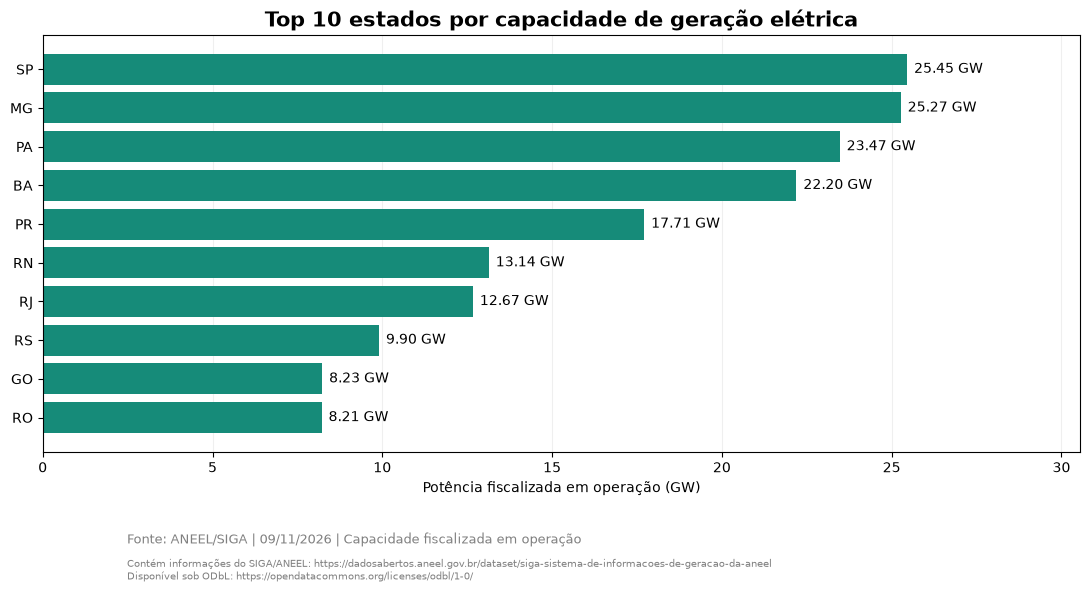

In [6]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

BASE_DIR = Path.cwd()

if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent

# Carregar Gold
df_estados = pd.read_parquet(
    BASE_DIR / "data" / "gold" / "aneel"
    / "capacidade_por_estado.parquet"
)

# Considerar somente usinas em operação
df_operacao = df_estados[
    df_estados["fase"] == "Operação"
].copy()

# Agregar por estado
ranking = (
    df_operacao.groupby("uf", as_index=False)
    .agg(potencia_mw=("potencia_mw", "sum"))
    .sort_values("potencia_mw", ascending=False)
    .head(10)
)

ranking["potencia_gw"] = ranking["potencia_mw"] / 1000

print("Top 10 estados:")
display(ranking)

# Ordenar para gráfico horizontal
ranking_plot = ranking.sort_values("potencia_gw")

fig, ax = plt.subplots(figsize=(11, 6))

barras = ax.barh(
    ranking_plot["uf"],
    ranking_plot["potencia_gw"],
    color="#168B79"
)

ax.bar_label(
    barras,
    labels=[
        f"{valor:.2f} GW"
        for valor in ranking_plot["potencia_gw"]
    ],
    padding=5
)

ax.set_xlim(
    0,
    ranking_plot["potencia_gw"].max() * 1.20
)

ax.set_title(
    "Top 10 estados por capacidade de geração elétrica",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Potência fiscalizada em operação (GW)")
ax.set_ylabel("")

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

fig.text(
    0.12, 0.085,
    "Fonte: ANEEL/SIGA | 09/11/2026 | "
    "Capacidade fiscalizada em operação",
    fontsize=9,
    color="gray"
)

fig.text(
    0.12, 0.025,
    "Contém informações do SIGA/ANEEL: https://dadosabertos.aneel.gov.br/dataset/siga-sistema-de-informacoes-de-geracao-da-aneel\n"
    "Disponível sob ODbL: https://opendatacommons.org/licenses/odbl/1-0/",
    fontsize=7.5,
    color="gray"
)

plt.tight_layout(rect=[0, 0.14, 1, 1])

PASTA_IMAGENS = BASE_DIR / "images"
PASTA_IMAGENS.mkdir(exist_ok=True)

plt.savefig(
    PASTA_IMAGENS / "10_capacidade_por_estado.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 6. Visualização 11 - Projetos de Expansão da Geração
Análise da potência outorgada de empreendimentos ainda não operacionais.

In [7]:

import pandas as pd
from pathlib import Path

BASE_DIR = Path.cwd()

if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent

df_estados = pd.read_parquet(
    BASE_DIR / "data" / "gold" / "aneel"
    / "capacidade_por_estado.parquet"
)

# Considerar somente projetos ainda não operacionais
fases_futuras = [
    "Construção",
    "Construção não iniciada"
]

df_projetos = df_estados[
    df_estados["fase"].isin(fases_futuras)
].copy()

# Consolidar por fase e tecnologia
df_expansao = (
    df_projetos.groupby(
        ["fase", "tipo_geracao"],
        as_index=False
    )
    .agg(
        potencia_mw=("potencia_mw", "sum"),
        empreendimentos=("empreendimentos", "sum")
    )
)

df_expansao["potencia_gw"] = (
    df_expansao["potencia_mw"] / 1000
)

print("Potência outorgada por fase:")
display(
    df_expansao.groupby("fase", as_index=False)
    .agg(
        potencia_gw=("potencia_gw", "sum"),
        empreendimentos=("empreendimentos", "sum")
    )
)

print("\nPotência outorgada por tecnologia:")
display(
    df_expansao.groupby("tipo_geracao", as_index=False)
    .agg(potencia_gw=("potencia_gw", "sum"))
    .sort_values("potencia_gw", ascending=False)
)


Potência outorgada por fase:


,fase,potencia_gw,empreendimentos
0,Construção,8.844899,126
1,Construção não iniciada,84.636427,1873



Potência outorgada por tecnologia:


,tipo_geracao,potencia_gw
3,UFV,61.184592
1,EOL,15.24528
5,UTE,14.117834
6,UTN,1.35
2,PCH,1.305458
4,UHE,0.259763
0,CGH,0.0184


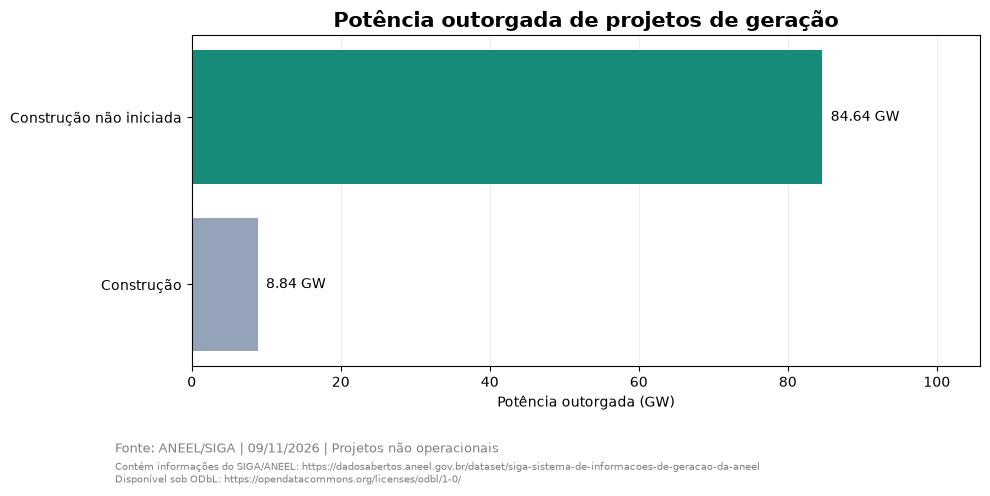

In [8]:

import matplotlib.pyplot as plt

resumo_fases = (
    df_expansao.groupby("fase", as_index=False)
    .agg(potencia_gw=("potencia_gw", "sum"))
    .sort_values("potencia_gw")
)

fig, ax = plt.subplots(figsize=(10, 5))

barras = ax.barh(
    resumo_fases["fase"],
    resumo_fases["potencia_gw"],
    color=["#94A3B8", "#168B79"]
)

ax.bar_label(
    barras,
    labels=[
        f"{v:.2f} GW"
        for v in resumo_fases["potencia_gw"]
    ],
    padding=6
)

ax.set_xlim(
    0,
    resumo_fases["potencia_gw"].max() * 1.25
)

ax.set_title(
    "Potência outorgada de projetos de geração",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Potência outorgada (GW)")
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

fig.text(
    0.12, 0.085,
    "Fonte: ANEEL/SIGA | 09/11/2026 | "
    "Projetos não operacionais",
    fontsize=9,
    color="gray"
)

fig.text(
    0.12, 0.025,
    "Contém informações do SIGA/ANEEL: https://dadosabertos.aneel.gov.br/dataset/siga-sistema-de-informacoes-de-geracao-da-aneel\n"
    "Disponível sob ODbL: https://opendatacommons.org/licenses/odbl/1-0/",
    fontsize=7.5,
    color="gray"
)

plt.tight_layout(rect=[0, 0.14, 1, 1])

PASTA_IMAGENS = BASE_DIR / "images"
PASTA_IMAGENS.mkdir(exist_ok=True)

plt.savefig(
    PASTA_IMAGENS / "11_projetos_expansao.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 7. Visualização 12 - Expansão por Fonte Energética
Distribuição da potência outorgada por tecnologia e fase dos projetos.

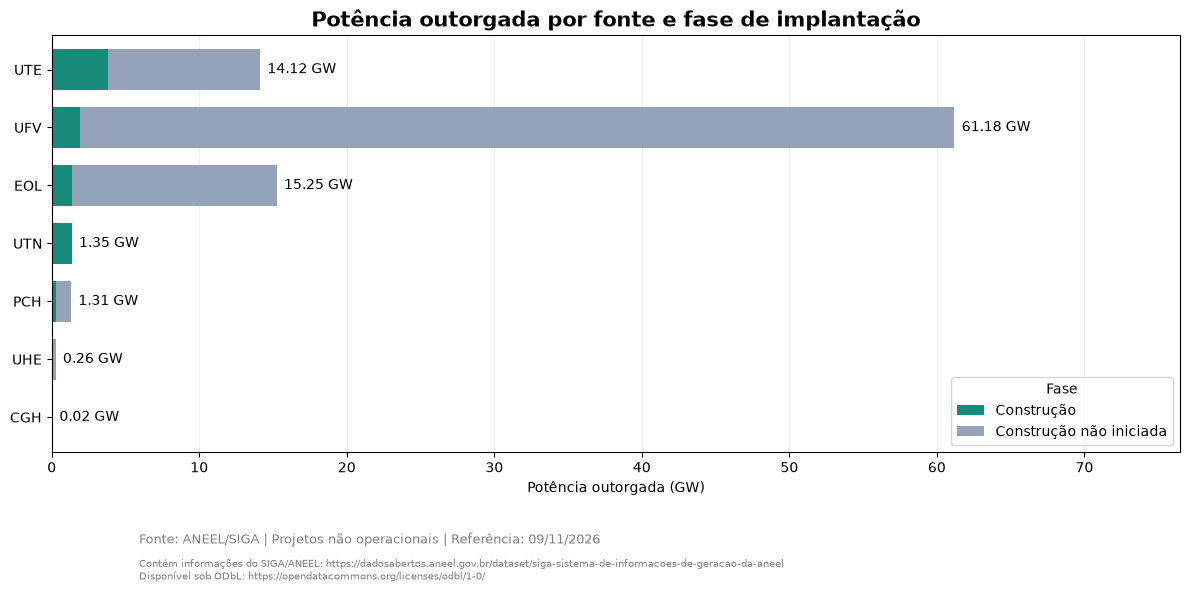

fase,Construção,Construção não iniciada,total_gw
tipo_geracao,,,
UFV,1.909209,59.275383,61.184592
EOL,1.3905,13.85478,15.24528
UTE,3.819979,10.297855,14.117834
UTN,1.35,0.0,1.35
PCH,0.321311,0.984147,1.305458
UHE,0.0484,0.211363,0.259763
CGH,0.0055,0.0129,0.0184


In [9]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Identificar a pasta do projeto
BASE_DIR = Path.cwd()

if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent

# Carregar a Gold da ANEEL
df_estados = pd.read_parquet(
    BASE_DIR / "data/gold/aneel/capacidade_por_estado.parquet"
)

# Selecionar projetos não operacionais
df_projetos = df_estados[
    df_estados["fase"].isin([
        "Construção",
        "Construção não iniciada"
    ])
].copy()

# Consolidar potência outorgada por fonte e fase
df_grafico = df_projetos.pivot_table(
    index="tipo_geracao",
    columns="fase",
    values="potencia_mw",
    aggfunc="sum",
    fill_value=0
) / 1000

fases = [
    "Construção",
    "Construção não iniciada"
]

df_grafico = df_grafico.reindex(
    columns=fases,
    fill_value=0
)

df_grafico = df_grafico.sort_values(
    by=fases,
    ascending=True
)

# Criar gráfico de barras empilhadas
fig, ax = plt.subplots(figsize=(12, 6))

df_grafico.plot(
    kind="barh",
    stacked=True,
    ax=ax,
    color=["#168B79", "#94A3B8"],
    width=0.7
)

# Mostrar total por tecnologia
totais = df_grafico.sum(axis=1)

for posicao, valor in enumerate(totais):
    ax.text(
        valor + 0.5,
        posicao,
        f"{valor:.2f} GW",
        va="center",
        fontsize=10
    )

ax.set_xlim(0, totais.max() * 1.25)

ax.set_title(
    "Potência outorgada por fonte e fase de implantação",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Potência outorgada (GW)")
ax.set_ylabel("")
ax.legend(title="Fase", loc="lower right")
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

fig.text(
    0.12, 0.085,
    "Fonte: ANEEL/SIGA | Projetos não operacionais | "
    "Referência: 09/11/2026",
    fontsize=9,
    color="gray"
)

fig.text(
    0.12, 0.025,
    "Contém informações do SIGA/ANEEL: https://dadosabertos.aneel.gov.br/dataset/siga-sistema-de-informacoes-de-geracao-da-aneel\n"
    "Disponível sob ODbL: https://opendatacommons.org/licenses/odbl/1-0/",
    fontsize=7.5,
    color="gray"
)

plt.tight_layout(rect=[0, 0.14, 1, 1])

# Salvar
PASTA_IMAGENS = BASE_DIR / "images"
PASTA_IMAGENS.mkdir(exist_ok=True)

plt.savefig(
    PASTA_IMAGENS / "12_expansao_por_fonte.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Tabela para conferência
display(
    df_grafico.assign(
        total_gw=totais
    ).sort_values("total_gw", ascending=False)
)
